### This notebook contains code to recreate model-based analyses of behaviour in the fMRI cohort (decision task). 

See fmri_behav_spatial_task for analyses of the attentional task, including relationship between attention biases and decisions

Code for Figure 2a,b,c,d & Supplementary figures 3e,f,g; 4d,e,f; 10a (and corresponding statistical tests)

To run this code, you need to use the processed behavioural data, found in the folder fmri_study/data/behav_data/processed/

To process the raw behavioural data from scratch, open the script 'preprocess_data' in the folder 'behav_preprocessing'

Eleanor Holton, 19/01/2024

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import statsmodels.api as sm
import scipy.stats as stats
import math
import pingouin as pg

import behav_functions as bf

ModuleNotFoundError: No module named 'pingouin'

In [ ]:
# set up rpy2 and packages to call mixed effects models (lme4)

%load_ext rpy2.ipython
#%reload_ext rpy2.ipython
import rpy2.robjects as ro
from rpy2.robjects.packages import importr

from rpy2.robjects import IntVector, FloatVector, FactorVector, globalenv
lme4 = importr('lme4')
lmerTest = importr('lmerTest')
base = importr('base')
stats = importr('stats')
#broom = importr('broom')
utils = importr('utils')

from rpy2.robjects import pandas2ri
pandas2ri.activate()
from rpy2.robjects.conversion import localconverter

R[write to console]: Error: package or namespace load failed for ‘lmerTest’ in loadNamespace(i, c(lib.loc, .libPaths()), versionCheck = vI[[i]]):
 namespace ‘rlang’ 1.0.4 is already loaded, but >= 1.1.0 is required

R[write to console]: Error in loadNamespace(i, c(lib.loc, .libPaths()), versionCheck = vI[[i]]) : 
  namespace ‘rlang’ 1.0.4 is already loaded, but >= 1.1.0 is required



RRuntimeError: Error in loadNamespace(i, c(lib.loc, .libPaths()), versionCheck = vI[[i]]) : 
  namespace ‘rlang’ 1.0.4 is already loaded, but >= 1.1.0 is required


In [3]:
# Parameters

nParticipants = 30
participants = range(nParticipants)

# plotting parameters
val_type_colours = ["#1E88E5", "#E66100"]
quartiles_colours = sns.color_palette("Purples")[:][2:6] 
model_colours = ["#D3D3D3","#D3D3D3", "#D3D3D3", quartiles_colours[3]]
bias_color='g'

small_label_fontsize = 15
medium_label_fontsize=18

In [4]:
## Import data 

base_folder = ''
data_folder = base_folder + '/data/mri_study/behaviour/'
figure_folder = ''

# Specify data folders for scan and post-scan testing sessions 
scanner_data_folder = data_folder + 'processed/scan_session/'
post_scanner_data_folder =data_folder + 'processed/post_scan_session/'

# Concatenate scanner and post-scanner data for full data set 
df_full = pd.DataFrame()
df_scanner = pd.DataFrame()
df_postscanner = pd.DataFrame()

for p in range(nParticipants):
    
    p_scanner = pd.read_csv(scanner_data_folder + 'scan_sub_' + str(p) + '.csv')
    p_postScanner = pd.read_csv(post_scanner_data_folder + 'post_scan_sub_' + str(p) + '.csv')
    
    #Merge total trials and total blocks across sessions in combined dataframe 
    scan_maxTrial = p_scanner['total_trial_number'].max()
    scan_maxBlock = p_scanner['block'].max()
    
    p_postScanner['total_trial_number']+=scan_maxTrial
    p_postScanner['block']+=scan_maxBlock
      
    df_full = pd.concat((df_full, p_scanner, p_postScanner))
    df_scanner = pd.concat((df_scanner, p_scanner))
    df_postscanner = pd.concat((df_postscanner, p_postScanner))

df_full = df_full.reset_index()
df_scanner = df_scanner.reset_index()
df_postscanner = df_postscanner.reset_index()

FileNotFoundError: [Errno 2] No such file or directory: '/data/mri_study/behaviour/processed/scan_session/scan_sub_0.csv'

##### Leave-one-out cross validation analysis

In [6]:
# set up model values
df_full['offer_max_value'] = df_full['mag_best_alt'] - df_full['mag_goal_item'] # offer max: best alternative offer magnitude – goal item offer magnitude 
df_full['myopic_switch_value'] = df_full['mag_best_alt'] - (df_full['mag_goal_item'] + df_full['net_contents']) # myopic: includes aggregated value (net contents) in value of goal item 
df_full['prosp_switch_value'] = df_full['prosp_best_alt_3'] - df_full['prosp_goal_item_3'] # see preprocessing for simple prospective value and sampler value 
df_full['sampler_switch_value'] = df_full['sampler_best_alt'] - df_full['sampler_goal_item']

In [14]:
%%R -i df_full,nParticipants -o m1,m2,m3,m4,m1_coef,m2_coef,m3_coef,m4_coef,m1_full,m2_full,m3_full,m4_full

# load libraries 
library(abind)
library(lme4)

# preallocate arrays for coefficients
m1_full <- array(numeric(),c(0,2)) 
m2_full <- array(numeric(),c(0,2)) 
m3_full <- array(numeric(),c(0,2)) 
m4_full <- array(numeric(),c(0,2)) 


for (i in 0:nParticipants) {
    
    # get subset of data without single participant
    p_df <- subset(df_full, participant != i)

    # fit mixed effects model to data subset 
    m1<-glmer('switch_trial ~ offer_max_value + (1 + offer_max_value | participant)',family=binomial, data=p_df)
    m2<-glmer('switch_trial ~ myopic_switch_value + (1 + myopic_switch_value | participant)',family=binomial, data=p_df)
    m3<-glmer('switch_trial ~ prosp_switch_value + (1 + prosp_switch_value | participant)',family=binomial, data=p_df)
    m4<-glmer('switch_trial ~ sampler_switch_value + (1 + sampler_switch_value | participant)',family=binomial, data=p_df)

    # collect coefficients 
    m1_coef = fixef(m1)
    m2_coef = fixef(m2)
    m3_coef = fixef(m3)
    m4_coef = fixef(m4)
    
    m1_full <- abind(m1_full, m1_coef, along=1)
    m2_full <- abind(m2_full, m2_coef, along=1)
    m3_full <- abind(m3_full, m3_coef, along=1)
    m4_full <- abind(m4_full, m4_coef, along=1)
    
}


R[write to console]: boundary (singular) fit: see help('isSingular')

Exception ignored from cffi callback <function _processevents at 0x170929080>:
Traceback (most recent call last):
  File "/Users/eleanorholton/anaconda3/envs/goalpursuit_env/lib/python3.11/site-packages/rpy2/rinterface_lib/callbacks.py", line 275, in _processevents
    @ffi_proxy.callback(ffi_proxy._processevents_def,
    
KeyboardInterrupt: 
R[write to console]: boundary (singular) fit: see help('isSingular')



In [ ]:
# save model coefficients in leave one out
np.savetxt(figure_folder+'R2.2_fulltask/kfold_offer_max.txt', m1_full)
np.savetxt(figure_folder+'R2.2_fulltask/kfold_myopic.txt', m2_full)
np.savetxt(figure_folder+'R2.2_fulltask/kfold_simple_prosp.txt', m3_full)
np.savetxt(figure_folder+'R2.2_fulltask/kfold_sample.txt', m4_full)

In [7]:
# load model coefficients (for future)
m1_full=np.loadtxt(figure_folder+'R2.2_fulltask/kfold_offer_max.txt')
m2_full=np.loadtxt(figure_folder+'R2.2_fulltask/kfold_myopic.txt')
m3_full=np.loadtxt(figure_folder+'R2.2_fulltask/kfold_simple_prosp.txt')
m4_full=np.loadtxt(figure_folder+'R2.2_fulltask/kfold_sample.txt')

In [8]:
# For each model, find the error for the remaining participant in LOO analysis

model_accuracy = np.full((4,len(participants)),np.nan)
switch_model_accuracy = np.full((4,len(participants)),np.nan)
stay_model_accuracy = np.full((4,len(participants)),np.nan)


for p_idx,p in enumerate(participants):
    
     # select the df for single left out participant
    p_df = df_full.loc[df_full['participant']==p,:]      
    
    for m, (model_df, val_name) in enumerate(zip([m1_full,m2_full,m3_full,m4_full], ['offer_max_value','myopic_switch_value','prosp_switch_value','sampler_switch_value'])):
        
 
        # get model coefficients
        coefs = model_df[p_idx,:]
        
        # get value of abandonment according to model 
        abandon_val = coefs[0] + coefs[1]*p_df[val_name]
            
        # calculate model predictions 
        pred = 1/(1+np.exp(-abandon_val))
        
        # difference between model prediction and outcome
        diff = 1-np.abs(p_df['switch_trial'] - pred)
        
        # cache mean model error
        model_accuracy[m,p_idx] = np.mean(diff)
        
        # switch trials only
        switch_model_accuracy[m,p_idx] = np.mean(diff[p_df['switch_trial']==1])
        
        # stay trials only
        stay_model_accuracy[m,p_idx] = np.mean(diff[p_df['switch_trial']==0])
        

(0.79, 0.89)

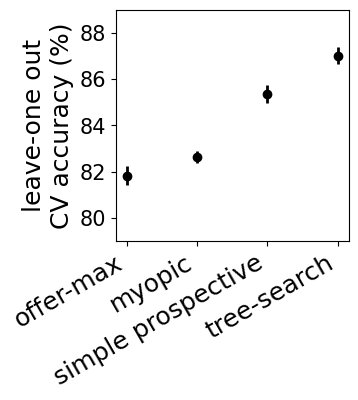

In [9]:
# Plot overall accuracy (Figure 2a)

fig,ax=plt.subplots(figsize=[3,3])
ax.scatter([0,1,2,3],np.mean(model_accuracy,1),color='k')
ax.errorbar([0,1,2,3],np.mean(model_accuracy,1),np.std(model_accuracy,1)/np.sqrt(len(participants)),linestyle='',linewidth=2,color='k')
ax.set_ylabel('leave-one out\nCV accuracy (%)',fontsize=18)
#ax.set_ylabel('Mean accuracy (%)\n (5-fold CV)',fontsize=medium_label_fontsize)
ax.set_xticks([0,1,2,3],['offer-max','myopic','simple prospective','tree-search'],rotation=30,fontsize=18,ha='right')
ax.set_yticks(np.arange(.80,.90,.02),np.arange(80,90,2),fontsize=small_label_fontsize)
ax.set_ylim([.79,.89])
#fig.savefig(figure_folder+'cv_all_trials.png',dpi=300, bbox_inches = "tight")

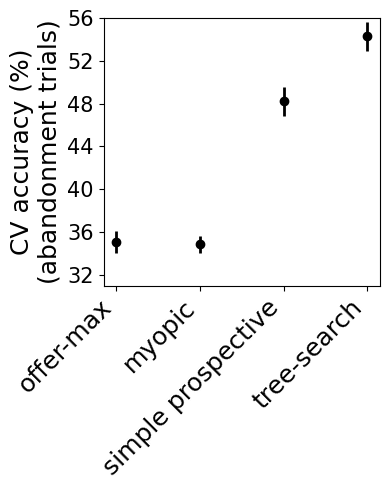

In [10]:
# Plot accuracy on abandonment trials only (Supplementary fig.3e)

fig,ax=plt.subplots(figsize=[4,5])
ax.scatter([0,1,2,3],np.mean(switch_model_accuracy,1),color='k')
ax.errorbar([0,1,2,3],np.mean(switch_model_accuracy,1),np.std(switch_model_accuracy,1)/np.sqrt(len(participants)),linestyle='',linewidth=2,color='k')
ax.set_ylabel('CV accuracy (%)\n(abandonment trials)',fontsize=medium_label_fontsize)
ax.set_xticks([0,1,2,3],['offer-max','myopic','simple prospective','tree-search'],rotation=45,fontsize=medium_label_fontsize,ha='right')
ax.set_yticks(np.arange(.32,.57,.04),np.arange(32,57,4),fontsize=small_label_fontsize)
ax.set_ylim([.31,.56])
fig.tight_layout()
#fig.savefig(figure_folder+'cv_abandonment_trials.png',dpi=300, bbox_inches = "tight")

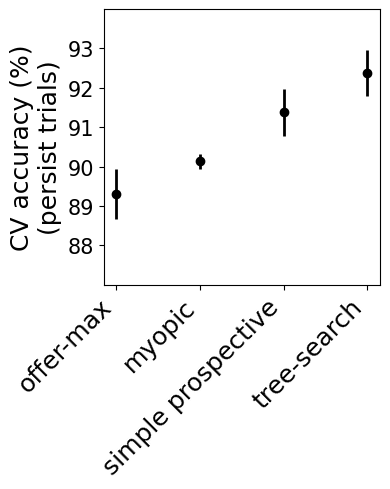

In [11]:
# Plot accuracy on persist trials only (Supplementary fig.3f)

fig,ax=plt.subplots(figsize=[4,5])
ax.scatter([0,1,2,3],np.mean(stay_model_accuracy,1),color='k')
ax.errorbar([0,1,2,3],np.mean(stay_model_accuracy,1),np.std(stay_model_accuracy,1)/np.sqrt(len(participants)),linestyle='',linewidth=2,color='k')
ax.set_ylabel('CV accuracy (%)\n(persist trials)',fontsize=medium_label_fontsize)
ax.set_xticks([0,1,2,3],['offer-max','myopic','simple prospective','tree-search'],rotation=45,fontsize=medium_label_fontsize,ha='right')
ax.set_yticks(np.arange(.88,.94,.01),np.arange(88,94,1),fontsize=small_label_fontsize)
ax.set_ylim([.87,.94])
fig.tight_layout()
#fig.savefig(figure_folder+'cv_persist_trials.png',dpi=300, bbox_inches = "tight")

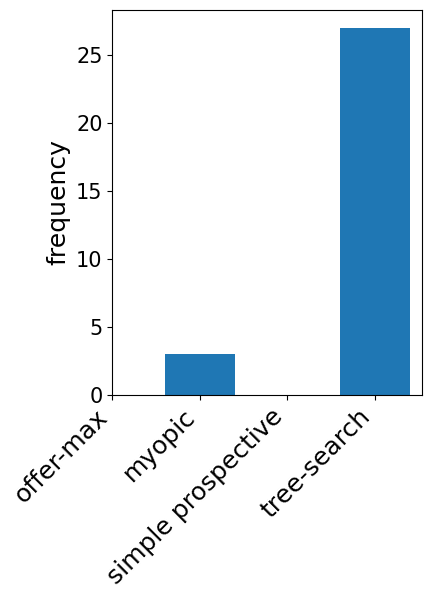

In [14]:
# Plot winning model across participants (Supplementary fig.3g)

win_models = np.argmax(model_accuracy,0)
unique_elements, counts = np.unique(win_models, return_counts=True)

fig,ax=plt.subplots(figsize=[4,5])
ax.bar(unique_elements,counts)
ax.set_xticks([0,1,2,3],['offer-max','myopic','simple prospective','tree-search'],rotation=45,fontsize=medium_label_fontsize,ha='right')
ax.set_ylabel('frequency',fontsize=medium_label_fontsize)
ax.set_yticks(range(0,30,5),range(0,30,5),fontsize=small_label_fontsize)

#fig.savefig(figure_folder+'model_frequencies.png',dpi=300, bbox_inches = "tight")

### Persistence bias analyses 

##### Persistence biases across individuals (fig.2b)

In [13]:
%%R -i df_full -o aggregate_mdl,aggregate_coefs

library(lme4)
library(lmerTest)

aggregate_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value|participant)',family=binomial, data=df_full)
aggregate_coefs <- fixef(aggregate_mdl)

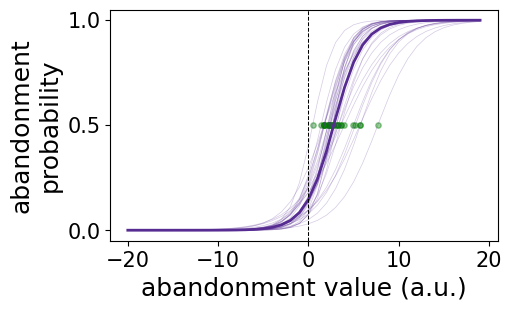

In [14]:
# Fit individual participant models and plot as subplot
fig, ax = plt.subplots(figsize=[5,3])

# Binomial regression for each participant
bias_const = []
sampler_betas = []
indifference_points = []

plot_range = np.arange(-20,20,1) # x range  

for p in participants:
    
    IP, bias_param, sampler_param = bf.find_indifference_point(df_full,p)
    bias_const.append(bias_param)
    sampler_betas.append(sampler_param)
    indifference_points.append(IP)
    
    # Plot individual sigmoid curves
    pred_switch = bias_param + (sampler_param*plot_range)
    prob_vals = [1/(1+math.exp(-x)) for x in pred_switch]
    
    ax.plot(plot_range, np.array(prob_vals),linewidth=0.5, alpha=0.25,color=model_colours[3])
    ax.scatter(IP,0.5,color=bias_color,s=15,alpha=0.4)
        
        
# Add aggregate line from mixed effects model
aggregate_pred_switch = aggregate_coefs[0] + (aggregate_coefs[1]*plot_range)
aggregate_prob_vals = [1/(1+math.exp(-x)) for x in aggregate_pred_switch]
ax.plot(plot_range, np.array(aggregate_prob_vals),linewidth=2,color=model_colours[3])

# Show sampler model indifference point at 0 
ax.axvline(0,color='k',linewidth=0.75,linestyle='--')

# Plot settings
ax.set_xticks(np.arange(-20,21,10))
ax.set_yticks(np.arange(0,1.25,.5))
ax.set_xlabel('abandonment value (a.u.)',fontsize=medium_label_fontsize)
ax.set_ylabel('abandonment\nprobability',fontsize=medium_label_fontsize)
ax.tick_params(axis='y', which='major', labelsize=small_label_fontsize)
ax.tick_params(axis='x', which='major', labelsize=small_label_fontsize)

fig.savefig(figure_folder+'indifference_points.png',dpi=300,bbox_inches='tight')

In [15]:
# statistics of indifference points against 0
import scipy.stats as stats
print(stats.normaltest(np.array(indifference_points)))
x = stats.wilcoxon(np.array(indifference_points),method = 'approx')
print(x)
print(x.zstatistic)

NormaltestResult(statistic=11.055425678626357, pvalue=0.003975070324583663)
WilcoxonResult(statistic=0.0, pvalue=1.7343976283205784e-06)
-4.782138900012879


##### Test-retest reliability of behavioural parameters (supplementary fig.4d,e,f)


across-session pearson correlation forpersistence bias 
PearsonRResult(statistic=0.6897755062334904, pvalue=2.4778549689447926e-05)

across-session pearson correlation forintercept 
PearsonRResult(statistic=0.46078517877263336, pvalue=0.010389857815559435)

across-session pearson correlation forinverse temp 
PearsonRResult(statistic=0.37662098813778017, pvalue=0.04022648162186085)


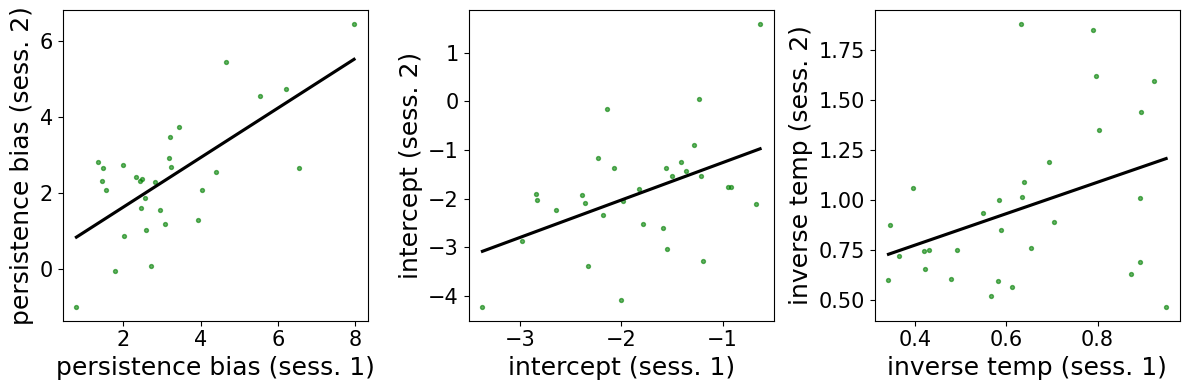

In [16]:
# set up model values
df_postscanner['sampler_switch_value'] = df_postscanner['sampler_best_alt'] - df_postscanner['sampler_goal_item']
df_scanner['sampler_switch_value'] = df_scanner['sampler_best_alt'] - df_scanner['sampler_goal_item']

indiv_session_df = pd.DataFrame(columns=['participant','IP_combined_sessions','bias_const_combined_sessions','sampler_betas_combined_sessions','IP_S','bias_const_S','sampler_betas_S','IP_postS','bias_const_postS','sampler_betas_postS'])
indiv_session_df['participant']=participants

# Add persistence biases fit to separate sessions
for p in participants:
    
    indiv_session_df.loc[indiv_session_df['participant']==p,'IP_S'], indiv_session_df.loc[indiv_session_df['participant']==p,'bias_const_S'], indiv_session_df.loc[indiv_session_df['participant']==p,'sampler_betas_S'] = bf.find_indifference_point(df_scanner,p)
    indiv_session_df.loc[indiv_session_df['participant']==p,'IP_postS'], indiv_session_df.loc[indiv_session_df['participant']==p,'bias_const_postS'], indiv_session_df.loc[indiv_session_df['participant']==p,'sampler_betas_postS'] = bf.find_indifference_point(df_postscanner,p)
    indiv_session_df.loc[indiv_session_df['participant']==p,'IP_combined_sessions'], indiv_session_df.loc[indiv_session_df['participant']==p,'bias_const_combined_sessions'], indiv_session_df.loc[indiv_session_df['participant']==p,'sampler_betas_combined_sessions'] = bf.find_indifference_point(df_full,p)
    
indiv_session_df = indiv_session_df.astype(float)

# Plot
fig,axes = plt.subplots(1,3,figsize=[12,4])

for i, (scanner_param,postscanner_param,label) in enumerate(zip(["IP_S","bias_const_S", "sampler_betas_S"],["IP_postS","bias_const_postS", "sampler_betas_postS"],["persistence bias ","intercept ","inverse temp "])):

    sns.regplot(ax=axes[i],data=indiv_session_df,x=scanner_param,y=postscanner_param,scatter_kws={"color": bias_color,'alpha':0.6,"s":8}, line_kws={"color": "black"},ci=None)   
    axes[i].set_xlabel(label +  '(sess. 1)',fontsize=medium_label_fontsize)
    axes[i].set_ylabel(label +  '(sess. 2)',fontsize=medium_label_fontsize)

    axes[i].tick_params(axis='y', which='major', labelsize=small_label_fontsize)
    axes[i].tick_params(axis='x', which='major', labelsize=small_label_fontsize)
    
    print('\nacross-session pearson correlation for' + label)
    print(stats.pearsonr(indiv_session_df[scanner_param],indiv_session_df[postscanner_param]))
    
fig.tight_layout()

fig.savefig(figure_folder+'test-retest.png',dpi=300,bbox_inches='tight')


In [18]:
# Save as parameter csv file
indiv_session_df.to_csv(base_folder + '/data/mri_study/behaviour/decision_task_parameters.csv')

In [44]:
# Using intraclass correlation as test-retest reliability test for main parameter of interest (persistence bias)

melted_df = pd.melt(indiv_session_df, id_vars=['participant'], value_vars=['IP_S','IP_postS'])
icc = pg.intraclass_corr(data=melted_df, targets='variable', raters='participant', ratings='value')
icc

,Type,Description,ICC,F,df1,df2,pval,CI95%
0,ICC1,Single raters absolute,0.076449,3.483323,1,58,0.067048,"[-0.01, 0.99]"
1,ICC2,Single random raters,0.095620,11.185247,1,29,0.002288,"[0.01, 0.99]"
2,ICC3,Single fixed raters,0.253457,11.185247,1,29,0.002288,"[0.03, 1.0]"
3,ICC1k,Average raters absolute,0.712918,3.483323,1,58,0.067048,"[-0.52, 1.0]"
4,ICC2k,Average random raters,0.760301,11.185247,1,29,0.002288,"[0.25, 1.0]"
5,ICC3k,Average fixed raters,0.910597,11.185247,1,29,0.002288,"[0.5, 1.0]"


SignificanceResult(statistic=-0.7664038335880912, pvalue=7.909313679368458e-07)


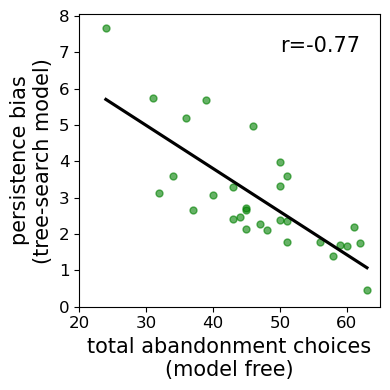

In [51]:
# For reviewers: correlation between persistence bias and abandonment
indiv_session_df['total_switches'] = df_full.groupby('participant')['switch_trial'].sum()
indiv_session_df['total_switches_insidescan'] = df_scanner.groupby('participant')['switch_trial'].sum()
fig,ax = plt.subplots(figsize=[4,4])

sns.regplot(ax=ax,data=indiv_session_df,x="total_switches",y="IP_combined_sessions",scatter_kws={"color":bias_color,'alpha':0.6,"s":25}, line_kws={"color": "black"},ci=None)   

ax.set_xlabel('total abandonment choices\n(model free)',fontsize=15)
ax.set_ylabel('persistence bias\n(tree-search model)',fontsize=15)

import scipy.stats as stats
a,b = stats.spearmanr(indiv_session_df['total_switches'], indiv_session_df['IP_combined_sessions'])
ax.text(50,7,'r='+str(round(a,2)),fontsize=15)
ax.set_yticks(range(0,9), range(0,9), fontsize=12)
ax.set_xticks(range(20,61,10), range(20,61,10), fontsize=12)

fig.tight_layout()
fig.savefig(figure_folder+'MF_treesearch_corr.png',dpi=300,bbox_inches='tight')

In [53]:
# get spearmans r 
corr_modelfree = stats.spearmanr(indiv_session_df['total_switches'], indiv_session_df['IP_combined_sessions'])
print(corr_modelfree)

# fisher transformation to get CI
stderr = 1.0 / math.sqrt(len(indiv_session_df['total_switches']) - 3)
delta = 1.96 * stderr
lower = math.tanh(math.atanh(corr_modelfree.statistic) - delta)
upper = math.tanh(math.atanh(corr_modelfree.statistic) + delta)
print(lower, upper)

SignificanceResult(statistic=-0.7664038335880912, pvalue=7.909313679368458e-07)
-0.8828968456971578 -0.5610412274843091


### Impact of goal progress on abandonment

In [54]:
%%R -i df_full -o aggregate_mdl,aggregate_mdl_GP,compare_goalProg

library(lme4)
library(lmerTest)

# Predict switch trials using the full-task model alone
aggregate_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value + prop_filled|participant)',family=binomial, data=df_full)

# Predict switch trials using the full-task model + goal progress
aggregate_mdl_GP<-glmer('switch_trial ~ sampler_switch_value + prop_filled + (1 +sampler_switch_value + prop_filled|participant)',family=binomial, data=df_full)
compare_goalProg<-anova(aggregate_mdl, aggregate_mdl_GP)

R[write to console]: boundary (singular) fit: see help('isSingular')



In [56]:
# Key stat: Comparison of nested mixed effects models (tree-search model +/- goal progress)
print(compare_goalProg)

                  npar          AIC          BIC       logLik     deviance  \
aggregate_mdl      8.0  4230.777163  4288.795929 -2107.388582  4214.777163   
aggregate_mdl_GP   9.0  4227.503529  4292.774640 -2104.751764  4209.503529   

                     Chisq   Df  Pr(>Chisq)  
aggregate_mdl          NaN  NaN         NaN  
aggregate_mdl_GP  5.273635  1.0    0.021651  


In [57]:
# Illustration of goal progress impact on persistence bias

byQuantity=0
byValue=1

# Method 1: equal quantity per bin
if byQuantity:
    df_full["progress_bin"] = np.nan
    df_full.loc[df_full['trial_number']>1,"progress_bin"]= pd.qcut(df_full['prop_filled'][df_full['trial_number']>1], q=4,labels = [1,2,3,4]).astype(float) # n.b. don't put first trials in bins
# Method 2: Bins defined strictly by value i.e. proportion filled 
elif byValue:
    prop_bins = np.arange(0,1.25,0.25)
    df_full["progress_bin"] = np.nan 
    df_full.loc[df_full['trial_number']>1,"progress_bin"]= pd.cut(df_full['prop_filled'][df_full['trial_number']>1], prop_bins,labels = [1,2,3,4],include_lowest=True).astype(float) # n.b. don't put first trials in bins


# Check sizes are reasonable
print(df_full.groupby(['progress_bin']).size()) # Should be equal quantity per bin 

M_quartiles = {}

for q in range(4):
    M_quartiles[q] = df_full.loc[df_full["progress_bin"]==q+1]

Q1_df = M_quartiles[0].reset_index() 
Q2_df = M_quartiles[1].reset_index() 
Q3_df = M_quartiles[2].reset_index() 
Q4_df = M_quartiles[3].reset_index() 

progress_bin
1.0    2698
2.0    3089
3.0    2323
4.0    2319
dtype: int64


In [58]:
%%R -i Q1_df,Q2_df,Q3_df,Q4_df -o Q1_mdl,Q2_mdl,Q3_mdl,Q4_mdl,Q1_coef,Q2_coef,Q3_coef,Q4_coef,Q1_se,Q2_se,Q3_se,Q4_se
library(lme4)
library(lmerTest)

Q1_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value|participant)',family=binomial, data=Q1_df)
Q2_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value|participant)',family=binomial, data=Q2_df)
Q3_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value|participant)',family=binomial, data=Q3_df)
Q4_mdl<-glmer('switch_trial ~ sampler_switch_value + (1 +sampler_switch_value|participant)',family=binomial, data=Q4_df)

Q1_coef = fixef(Q1_mdl)
Q2_coef = fixef(Q2_mdl)
Q3_coef = fixef(Q3_mdl)
Q4_coef = fixef(Q4_mdl)

Q1_se = summary(Q1_mdl)$coef[, 2, drop = FALSE]
Q2_se = summary(Q2_mdl)$coef[, 2, drop = FALSE]
Q3_se = summary(Q3_mdl)$coef[, 2, drop = FALSE]
Q4_se = summary(Q4_mdl)$coef[, 2, drop = FALSE]

R[write to console]: boundary (singular) fit: see help('isSingular')

R[write to console]: boundary (singular) fit: see help('isSingular')



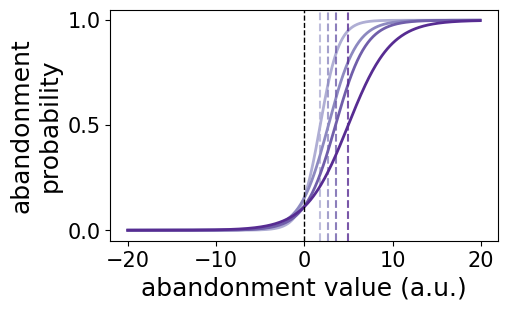

In [60]:
# Plot

quartiles_intercepts = np.array((Q1_coef[0],Q2_coef[0],Q3_coef[0],Q4_coef[0]))
quartiles_betas = np.array((Q1_coef[1],Q2_coef[1],Q3_coef[1],Q4_coef[1]))

# Plot by quartile
fig, ax = plt.subplots(figsize=[5,3])
#plot_range = np.arange(-3,3,0.01)
plot_range = np.arange(-20,20,0.1)
labels = ['<25','25-50','50-75','>75']

# Plot separate bias for each quartile 
for q in range(4):
    
    intercept = quartiles_intercepts[q]
    sampler_coef = quartiles_betas[q]

    # Plot sigmoid
    aggregate_pred_switch = intercept + (sampler_coef*plot_range)
    aggregate_prob_vals = [math.exp(x)/(1+math.exp(x)) for x in aggregate_pred_switch]
    leglab = labels[q]
    ax.plot(plot_range, np.array(aggregate_prob_vals),linewidth=2,color=quartiles_colours[q],label=leglab)
    
    # Add bias lines
    IP = -intercept / sampler_coef
    ax.axvline(IP,color=quartiles_colours[q],alpha=0.8,linestyle='--',label='_nolegend_',)

# Add reference point at 0
ax.axvline(0,color='k',linewidth=1,linestyle='--')

# Plot settings
ax.set_yticks(np.arange(0,1.25,.5))
ax.set_xlabel('abandonment value (a.u.)',fontsize=medium_label_fontsize)
ax.set_ylabel('abandonment\nprobability',fontsize=medium_label_fontsize)
ax.tick_params(axis='y', which='major', labelsize=small_label_fontsize)
ax.tick_params(axis='x', which='major', labelsize=small_label_fontsize)

#fig.savefig(figure_folder+'quartiles_indifference_point.png',bbox_inches='tight',dpi=300)


### Temptation / frustration analyses
#### Impact of alternative goal value diminishes more than impact of current goal value


In [65]:
#A dd interaction terms 
df_full['best_alt_x_goal_progress'] = df_full['sampler_best_alt'] * df_full['prop_filled']
df_full['goal_x_goal_progress'] = df_full['sampler_goal_item'] * df_full['prop_filled']
df_full['constant'] = 1

# pre-allocate lists 
indiv_interaction_reg_mdls = {}
bestAlt_interaction_betas = []
goalItem_interaction_betas = []

# Fit logistic regression to each participant

for i,p in enumerate(participants): 
    
    p_df = df_full.loc[df_full['participant']==p,:]
    
    endog = df_full.loc[(df_full["sampler_switch_value"].notna()) & (df_full["participant"]==p),"switch_trial"]
    exog = sm.add_constant(df_full.loc[(df_full["sampler_switch_value"].notna()) & (df_full["participant"]==p),["sampler_best_alt",'sampler_goal_item','prop_filled','best_alt_x_goal_progress','goal_x_goal_progress']])

    glm_binom = sm.GLM(endog, exog, family=sm.families.Binomial())
    result = glm_binom.fit()
  
    # append parameters
    indiv_interaction_reg_mdls[i] = result
    bestAlt_interaction_betas.append(result.params.best_alt_x_goal_progress)
    goalItem_interaction_betas.append(result.params.goal_x_goal_progress)

# Tests of beta coefficients
print('\ncurrent goal x goal progress:')
goalitem_beta_stat = stats.ttest_1samp(goalItem_interaction_betas,popmean=0)
print(goalitem_beta_stat)
print(goalitem_beta_stat.confidence_interval(.95))
print(bf.cohen_d_paired(np.array(goalItem_interaction_betas), 0))

print('\nalternative goal x goal progress:')
bestalt_beta_stat = stats.ttest_1samp(bestAlt_interaction_betas,popmean=0)
print(bestalt_beta_stat)
print(bestalt_beta_stat.confidence_interval(.95))
print(bf.cohen_d_paired(np.array(bestAlt_interaction_betas), 0))

print('\ntest for difference between interaction slopes:')
beta_compare_stat = stats.ttest_rel(bestAlt_interaction_betas, np.negative(goalItem_interaction_betas))
print(beta_compare_stat) # test against sign flipped current goal value because of opposing impact of current and alternative goal
print(beta_compare_stat.confidence_interval(.95))
print(bf.cohen_d_paired(np.array(bestAlt_interaction_betas), np.negative(goalItem_interaction_betas)))



current goal x goal progress:
TtestResult(statistic=7.088057243641819, pvalue=8.476442872078346e-08, df=29)
ConfidenceInterval(low=0.3922848255786774, high=0.710484302868866)
1.3162191868763695

alternative goal x goal progress:
TtestResult(statistic=-7.973394283133608, pvalue=8.570915371402352e-09, df=29)
ConfidenceInterval(low=-0.9557767882224788, high=-0.5655469456579385)
-1.4806221478254675

test for difference between interaction slopes:
TtestResult(statistic=-3.389616174991333, pvalue=0.0020347976744539667, df=29)
ConfidenceInterval(low=-0.3355512289795868, high=-0.08300337645328709)
-0.6294359219054206


##### Illustration of current/alternative goal asymmetry in quartile bins 


In [68]:
%%R -i Q1_df,Q2_df,Q3_df,Q4_df -o Q1_split_mdl,Q2_split_mdl,Q3_split_mdl,Q4_split_mdl,Q1_coef,Q2_coef,Q3_coef,Q4_coef,Q1_se,Q2_se,Q3_se,Q4_se
library(lme4)
library(lmerTest)

Q1_split_mdl<-glmer('switch_trial ~ sampler_goal_item + sampler_best_alt + (1 +sampler_goal_item + sampler_best_alt|participant)',family=binomial, data=Q1_df)
Q2_split_mdl<-glmer('switch_trial ~ sampler_goal_item + sampler_best_alt + (1 +sampler_goal_item + sampler_best_alt|participant)',family=binomial, data=Q2_df)
Q3_split_mdl<-glmer('switch_trial ~ sampler_goal_item + sampler_best_alt + (1 +sampler_goal_item + sampler_best_alt|participant)',family=binomial, data=Q3_df)
Q4_split_mdl<-glmer('switch_trial ~ sampler_goal_item + sampler_best_alt + (1 +sampler_goal_item + sampler_best_alt|participant)',family=binomial, data=Q4_df)

Q1_coef = fixef(Q1_split_mdl)
Q2_coef = fixef(Q2_split_mdl)
Q3_coef = fixef(Q3_split_mdl)
Q4_coef = fixef(Q4_split_mdl)

Q1_se = summary(Q1_split_mdl)$coef[, 2, drop = FALSE]
Q2_se = summary(Q2_split_mdl)$coef[, 2, drop = FALSE]
Q3_se = summary(Q3_split_mdl)$coef[, 2, drop = FALSE]
Q4_se = summary(Q4_split_mdl)$coef[, 2, drop = FALSE]


R[write to console]: boundary (singular) fit: see help('isSingular')



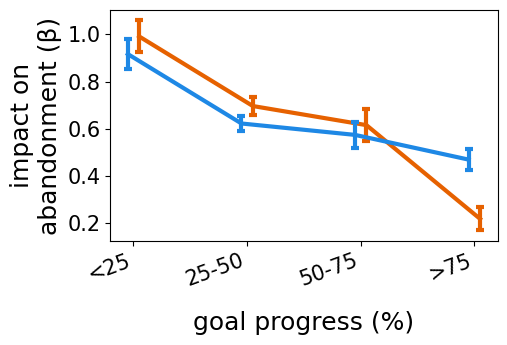

In [71]:
# Get coefs from R
chosen_quartiles = np.array((Q1_coef[1], Q2_coef[1], Q3_coef[1], Q4_coef[1]))
chosen_quartiles_SE = np.array((Q1_se[1], Q2_se[1], Q3_se[1], Q4_se[1]))

alt_quartiles = np.array((Q1_coef[2], Q2_coef[2], Q3_coef[2], Q4_coef[2]))
alt_quartiles_SE = np.array((Q1_se[2], Q2_se[2], Q3_se[2], Q4_se[2]))

bias_quartiles = np.array((Q1_coef[0], Q2_coef[0], Q3_coef[0], Q4_coef[0]))
bias_quartiles_SE = np.array((Q1_se[0], Q2_se[0], Q3_se[0], Q4_se[0]))

# Plot
labels = ['<25','25-50','50-75','>75']

x = np.arange(len(labels))  # the label locations
linewidth = 3  # the width of the line

offset=0.05

fig, ax = plt.subplots(figsize=[5,3])#figsize=[5,6])
ax.plot(x + offset, np.squeeze((alt_quartiles)), linewidth=linewidth, label='alternative goal value',color=val_type_colours[1])
(_, caps2, _) = ax.errorbar(x + offset, np.squeeze((alt_quartiles)), yerr=np.squeeze(alt_quartiles_SE),color=val_type_colours[1],ls='none',capsize=3,linewidth=linewidth)

# add sign-flipped current goal value for illustration
ax.plot(x - offset, np.squeeze(np.negative(chosen_quartiles)), linewidth=linewidth,color=val_type_colours[0])
(_, caps3, _) = ax.errorbar(x - offset, np.squeeze(np.negative(chosen_quartiles)), yerr=np.squeeze(chosen_quartiles_SE),color=val_type_colours[0],ls='none',capsize=3,linewidth=linewidth)


for a,b in zip(caps2,caps3):
    a.set_markeredgewidth(linewidth)
    b.set_markeredgewidth(linewidth)

ax.set_ylabel('impact on\nabandonment (β)',fontsize=medium_label_fontsize)
ax.set_xlabel('goal progress (%)',fontsize=medium_label_fontsize,labelpad=15)
ax.set_xticks(x, labels,rotation=20,ha='right')
ax.tick_params(axis='x', which='major', labelsize=small_label_fontsize)
ax.tick_params(axis='y', which='major', labelsize=small_label_fontsize)

#fig.savefig(figure_folder+'current_alternative_goal_asymmetry.png',bbox_inches='tight',dpi=300)